<a href="https://colab.research.google.com/github/weiogoh/Final-Year-Project-Applying-Machine-Learning-for-Data-Drive-Classification-of-Physical-Systems/blob/main/setting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install google-genai -q

import os
from google.colab import drive, userdata
from google import genai

try:
    drive.mount('/content/drive')
    project_folder = '/content/drive/MyDrive/Classifier'
    if os.path.exists(project_folder):
        os.chdir(project_folder)
        print(f"📁 Success! Locked into Drive folder: {os.getcwd()}")
    else:
        print(f"❌ Error: Cannot find folder '{project_folder}'. Checking path...")
        os.chdir('/content/drive/MyDrive')
        print(f"📁 Fallback active. Locked into main Drive: {os.getcwd()}")
except Exception as drive_error:
    print(f"❌ Drive Mount Failed: {drive_error}")
    print("💡 Troubleshooting: Make sure you accept the authorization popup. If the popup didn't show, check if your browser blocks third-party cookies or try running this in Incognito Mode.")

!git config --global user.name "weiogoh"
!git config --global user.email "297090785+weiogoh@users.noreply.github.com"

try:
    client = genai.Client(api_key=userdata.get('GEMINI_API_KEY'))
    response = client.models.generate_content(
        model='gemini-3.8-flash',
        contents="Hello! Identify your model version and confirm you are connected to my Colab workspace."
    )
    print("\n🤖 === GEMINI MCP CHAT HANDSHAKE ===")
    print(response.text.strip())
    print("=======================================")
except Exception as e:
    print(f"\n❌ Core Setup Failed: Check your Colab Secret Keys or API Key! Error: {e}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📁 Success! Locked into Drive folder: /content/drive/MyDrive/Classifier

❌ Core Setup Failed: Check your Colab Secret Keys or API Key! Error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}


In [ ]:
from google.colab import userdata

try:
    api_key = userdata.get('GEMINI_API_KEY')
    if not api_key:
        print("❌ Verification Failed: The secret 'GEMINI_API_KEY' exists but is empty.")
    else:
        print("✅ Success: 'GEMINI_API_KEY' is correctly configured in your Colab Secrets!")
        print(f"🔑 Key starts with: '{api_key[:4]}...' and has a length of {len(api_key)} characters.")
except userdata.SecretNotFoundError:
    print("❌ Verification Failed: Could not find any secret named 'GEMINI_API_KEY' in your Colab Secrets.")
    print("💡 How to fix: Click the key icon (🔑) on the left sidebar in Colab, add a new secret with the Name 'GEMINI_API_KEY', paste your key as the Value, and turn on the toggle for 'Notebook access'.")
except Exception as e:
    print(f"❌ An unexpected error occurred: {e}")

✅ Success: 'GEMINI_API_KEY' is correctly configured in your Colab Secrets!
🔑 Key starts with: 'AQ.A...' and has a length of 53 characters.


In [ ]:
!pip install pypdf -q

import os
from pypdf import PdfReader

# Search for GHS-related PDFs in the directory
drive_path = '/content/drive/MyDrive'
files = os.listdir(drive_path)
ghs_pdfs = [f for f in files if 'ghs' in f.lower() or 'classification' in f.lower() or 'prediction' in f.lower()]

print(f"Found matching PDFs: {ghs_pdfs}")

for pdf_file in ghs_pdfs:
    full_path = os.path.join(drive_path, pdf_file)
    print(f"\n--- Reading: {pdf_file} ---")
    try:
        reader = PdfReader(full_path)
        text = ""
        # Read the first 3 pages to understand the context and overview
        for i in range(min(3, len(reader.pages))):
            text += reader.pages[i].extract_text() + "\n"
        print(text[:2000]) # Print first 2000 characters of overview
    except Exception as e:
        print(f"Could not read {pdf_file}: {e}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.1/405.1 kB 4.2 MB/s eta 0:00:00
Found matching PDFs: ['direct-prediction-of-chemical-hazards-in-ghs-classification-using-smiles-representation-for-health-and-safety_copy.pdf']

--- Reading: direct-prediction-of-chemical-hazards-in-ghs-classification-using-smiles-representation-for-health-and-safety_copy.pdf ---
Direct Prediction of Chemical Hazards in GHS Classification Using
SMILES Representation for Health and Safety Applications
Published as part of ACS Chemical Health & Safety special issue “The Chemical Exposure Multiverse”.
Takaaki Harada,* Rumiko Hayashi, and Kengo Tomita
Cite This: ACS Chem. Health Saf. 2025, 32, 440−448
 Read Online
ACCESS
 Metrics & More
 Article Recommendations *sı Supporting Information
ABSTRACT: Physical, health, and environmental hazards of
chemicalsubstancesareclassifiedintohazardclassesintheGlobally
Harmonized System of Classification and Labeling of Chemicals
(GHS). Within each hazard class in the GHS cla

In [ ]:
import os

# Focus entirely on the Classifier directory as requested
classifier_path = '/content/drive/MyDrive/Classifier'

try:
    if os.path.exists(classifier_path):
        files = os.listdir(classifier_path)
        print(f"📁 Inside 'Classifier' folder: {len(files)} items found.\n")
        for f in files:
            print(f" - {f}")
    else:
        print(f"❌ Folder not found at {classifier_path}")
except Exception as e:
    print(f"❌ Error accessing folder: {e}")

📁 Inside 'Classifier' folder: 10 items found.

 - Full data.csv
 - Testing.ipynb
 - plotting.ipynb
 - Train model.ipynb
 - Training Data.ipynb
 - Test data.ipynb
 - features selection.ipynb
 - features.csv
 - top5_feature_importances.csv
 - GHS Chemical Hazard Classification blueprint.pdf


In [ ]:
from pypdf import PdfReader

blueprint_path = '/content/drive/MyDrive/Classifier/GHS Chemical Hazard Classification blueprint.pdf'

try:
    reader = PdfReader(blueprint_path)
    print(f"📖 Successfully opened: {blueprint_path}")
    print(f"📄 Total pages: {len(reader.pages)}\n")

    # Read all pages to get a complete understanding of the workflow
    full_text = ""
    for idx, page in enumerate(reader.pages):
        page_text = page.extract_text()
        print(f"=== PAGE {idx + 1} ===")
        print(page_text[:3000])  # Printing first 3000 chars of each page
        print("\n" + "="*20 + "\n")
except Exception as e:
    print(f"❌ Failed to read the PDF: {e}")

📖 Successfully opened: /content/drive/MyDrive/Classifier/GHS Chemical Hazard Classification blueprint.pdf
📄 Total pages: 3

=== PAGE 1 ===
GHS Chemical Hazard Classification 
Refined Technical Blueprint & Workflow Specifications 
Workflow Overview 
This revised workflow simplifies preprocessing by omitting initial feature selection during 
data sampling. Stage 1 generates 10 random 80/20 train/test pool splits where the test set is 
the exact complement of the training set. Stage 2 filters features and trains 10 Random 
Forest models exported via pickle. Stage 3 creates pairwise evaluation sets and tracks 
sample ratios. Stage 4 performs imbalance stress testing (1: 𝑎 capped at 1: 10, and flipped 
𝑎: 1) with dynamic candidate pictogram selection in Small Sample Mode. Stage 5 compiles 
F1-scores into structured summary CSV files. 
Stage 1: Data Sampling & Dataset Generation 
• 1.1 Load Full Dataset: Prompt user for full_data.csv file path. 
• 1.2 Label Parsing: Clean Pictogram(s) column

In [ ]:
from pypdf import PdfReader

blueprint_path = '/content/drive/MyDrive/Classifier/GHS Chemical Hazard Classification blueprint.pdf'

try:
    reader = PdfReader(blueprint_path)
    print(f"📖 Successfully opened: {blueprint_path}")
    print(f"📄 Total pages: {len(reader.pages)}\n")

    # Read all pages to get a complete understanding of the workflow
    full_text = ""
    for idx, page in enumerate(reader.pages):
        page_text = page.extract_text()
        print(f"=== PAGE {idx + 1} ===")
        print(page_text[:3000])  # Printing first 3000 chars of each page
        print("\n" + "="*20 + "\n")
except Exception as e:
    print(f"❌ Failed to read the PDF: {e}")

📖 Successfully opened: /content/drive/MyDrive/Classifier/GHS Chemical Hazard Classification blueprint.pdf
📄 Total pages: 3

=== PAGE 1 ===
GHS Chemical Hazard Classification 
Refined Technical Blueprint & Workflow Specifications 
Workflow Overview 
This revised workflow simplifies preprocessing by omitting initial feature selection during 
data sampling. Stage 1 generates 10 random 80/20 train/test pool splits where the test set is 
the exact complement of the training set. Stage 2 filters features and trains 10 Random 
Forest models exported via pickle. Stage 3 creates pairwise evaluation sets and tracks 
sample ratios. Stage 4 performs imbalance stress testing (1: 𝑎 capped at 1: 10, and flipped 
𝑎: 1) with dynamic candidate pictogram selection in Small Sample Mode. Stage 5 compiles 
F1-scores into structured summary CSV files. 
Stage 1: Data Sampling & Dataset Generation 
• 1.1 Load Full Dataset: Prompt user for full_data.csv file path. 
• 1.2 Label Parsing: Clean Pictogram(s) column

In [ ]:
from pypdf import PdfReader

blueprint_path = '/content/drive/MyDrive/Classifier/GHS Chemical Hazard Classification blueprint.pdf'

try:
    reader = PdfReader(blueprint_path)
    print(f"📖 Successfully opened: {blueprint_path}")
    print(f"📄 Total pages: {len(reader.pages)}\n")

    for idx, page in enumerate(reader.pages):
        print(f"=== PAGE {idx + 1} ===")
        print(page.extract_text())
        print("\n" + "="*40 + "\n")
except Exception as e:
    print(f"❌ Failed to read the PDF: {e}")

📖 Successfully opened: /content/drive/MyDrive/Classifier/GHS Chemical Hazard Classification blueprint.pdf
📄 Total pages: 3

=== PAGE 1 ===
GHS Chemical Hazard Classification 
Refined Technical Blueprint & Workflow Specifications 
Workflow Overview 
This revised workflow simplifies preprocessing by omitting initial feature selection during 
data sampling. Stage 1 generates 10 random 80/20 train/test pool splits where the test set is 
the exact complement of the training set. Stage 2 filters features and trains 10 Random 
Forest models exported via pickle. Stage 3 creates pairwise evaluation sets and tracks 
sample ratios. Stage 4 performs imbalance stress testing (1: 𝑎 capped at 1: 10, and flipped 
𝑎: 1) with dynamic candidate pictogram selection in Small Sample Mode. Stage 5 compiles 
F1-scores into structured summary CSV files. 
Stage 1: Data Sampling & Dataset Generation 
• 1.1 Load Full Dataset: Prompt user for full_data.csv file path. 
• 1.2 Label Parsing: Clean Pictogram(s) column

In [ ]:
from pypdf import PdfReader
import os

blueprint_path = '/content/drive/MyDrive/Classifier/GHS Chemical Hazard Classification blueprint.pdf'

if os.path.exists(blueprint_path):
    try:
        reader = PdfReader(blueprint_path)
        print(f"📄 PDF loaded successfully. Total pages: {len(reader.pages)}\n")
        for idx in range(len(reader.pages)):
            print(f"--- Page {idx + 1} ---")
            print(reader.pages[idx].extract_text())
            print("\n" + "="*50 + "\n")
    except Exception as e:
        print(f"❌ Error reading PDF: {e}")
else:
    print(f"❌ Blueprint PDF not found at {blueprint_path}")

📄 PDF loaded successfully. Total pages: 3

--- Page 1 ---
GHS Chemical Hazard Classification 
Refined Technical Blueprint & Workflow Specifications 
Workflow Overview 
This revised workflow simplifies preprocessing by omitting initial feature selection during 
data sampling. Stage 1 generates 10 random 80/20 train/test pool splits where the test set is 
the exact complement of the training set. Stage 2 filters features and trains 10 Random 
Forest models exported via pickle. Stage 3 creates pairwise evaluation sets and tracks 
sample ratios. Stage 4 performs imbalance stress testing (1: 𝑎 capped at 1: 10, and flipped 
𝑎: 1) with dynamic candidate pictogram selection in Small Sample Mode. Stage 5 compiles 
F1-scores into structured summary CSV files. 
Stage 1: Data Sampling & Dataset Generation 
• 1.1 Load Full Dataset: Prompt user for full_data.csv file path. 
• 1.2 Label Parsing: Clean Pictogram(s) column and parse into binary indicator columns 
(0/1) for all 9 GHS categories: Acute t

In [ ]:
import os
import json

classifier_dir = '/content/drive/MyDrive/Classifier'
notebook_files = [f for f in os.listdir(classifier_dir) if f.endswith('.ipynb')]

print(f"🔍 Found {len(notebook_files)} notebooks to inspect: {notebook_files}\n")

for nb_file in notebook_files:
    nb_path = os.path.join(classifier_dir, nb_file)
    print(f"==================================================")
    print(f"📖 Auditing Notebook: {nb_file}")
    print(f"==================================================")
    try:
        with open(nb_path, 'r', encoding='utf-8') as f:
            nb_data = json.load(f)

        cells = nb_data.get('cells', [])
        code_cells_count = sum(1 for c in cells if c.get('cell_type') == 'code')
        print(f"📊 Total Cells: {len(cells)} ({code_cells_count} code cells)\n")

        # Print non-empty code snippets/headers from the notebook to understand its structure
        snippet_count = 0
        for i, cell in enumerate(cells):
            cell_type = cell.get('cell_type')
            source = "".join(cell.get('source', []))
            if not source.strip():
                continue

            if cell_type == 'markdown':
                # Print headers
                lines = source.split('\n')
                headers = [line for line in lines if line.strip().startswith('#')]
                if headers:
                    print(f"  [Cell {i} Markdown Headers]:")
                    for h in headers:
                        print(f"    {h}")
            elif cell_type == 'code':
                snippet_count += 1
                if snippet_count <= 8:  # Limit output length
                    print(f"  [Cell {i} Code Snippet (First 5 lines)]:")
                    code_lines = source.split('\n')[:5]
                    for line in code_lines:
                        print(f"    {line}")
                    print()
        if snippet_count > 8:
            print(f"  ... and {snippet_count - 8} more code cells.")
    except Exception as e:
        print(f"❌ Failed to read {nb_file}: {e}")
    print("\n")

🔍 Found 6 notebooks to inspect: ['Testing.ipynb', 'plotting.ipynb', 'Train model.ipynb', 'Training Data.ipynb', 'Test data.ipynb', 'features selection.ipynb']

📖 Auditing Notebook: Testing.ipynb
📊 Total Cells: 1 (1 code cells)

  [Cell 0 Code Snippet (First 5 lines)]:
    import pickle
    import pandas as pd
    from sklearn.metrics import accuracy_score,confusion_matrix,f1_score,precision_score,recall_score
    
    name_tag = {1: "Irritant",2: "Acute Toxic",3: "Corrosive",4: "Environmental Hazard",5: "Flammable",6: "Health Hazard",7: "Compressed Gas",8: "Explosive",9: "Oxidizer",10: "NaN",}



📖 Auditing Notebook: plotting.ipynb
📊 Total Cells: 3 (3 code cells)

  [Cell 0 Code Snippet (First 5 lines)]:
    #ghs vs f1-score each run each ghs
    
    import pandas as pd
    import matplotlib.pyplot as plt
    

  [Cell 1 Code Snippet (First 5 lines)]:
    #run vs f1-score each ghs
    
    import pandas as pd
    import matplotlib.pyplot as plt
    

  [Cell 2 Code Snippet (First 5 li

In [ ]:
import os

classifier_dir = '/content/drive/MyDrive/Classifier'
files = os.listdir(classifier_dir)

# Filter for common image file formats
image_extensions = ('.png', '.jpg', '.jpeg', '.svg', '.pdf')
image_files = [f for f in files if f.lower().endswith(image_extensions) and not f.endswith('blueprint.pdf')]

print(f"📊 Found {len(image_files)} image result files to analyze:")
for img in image_files:
    print(f" - {img}")

📊 Found 18 image result files to analyze:
 - run vs f1 Acute Toxic.png
 - run vs avg f1 Acute Toxic.png
 - run vs avg f1 Compressed Gas.png
 - run vs f1 Compressed Gas.png
 - run vs f1 Corrosive.png
 - run vs avg f1 Corrosive.png
 - run vs f1 Environmental Hazard.png
 - run vs avg f1 Environmental Hazard.png
 - run vs f1 Explosive.png
 - run vs avg f1 Explosive.png
 - run vs f1 Flammable.png
 - run vs avg f1 Flammable.png
 - run vs avg f1 Health Hazard.png
 - run vs f1 Health Hazard.png
 - run vs avg f1 Irritant.png
 - run vs f1 Irritant.png
 - run vs avg f1 Oxidizer.png
 - run vs f1 Oxidizer.png


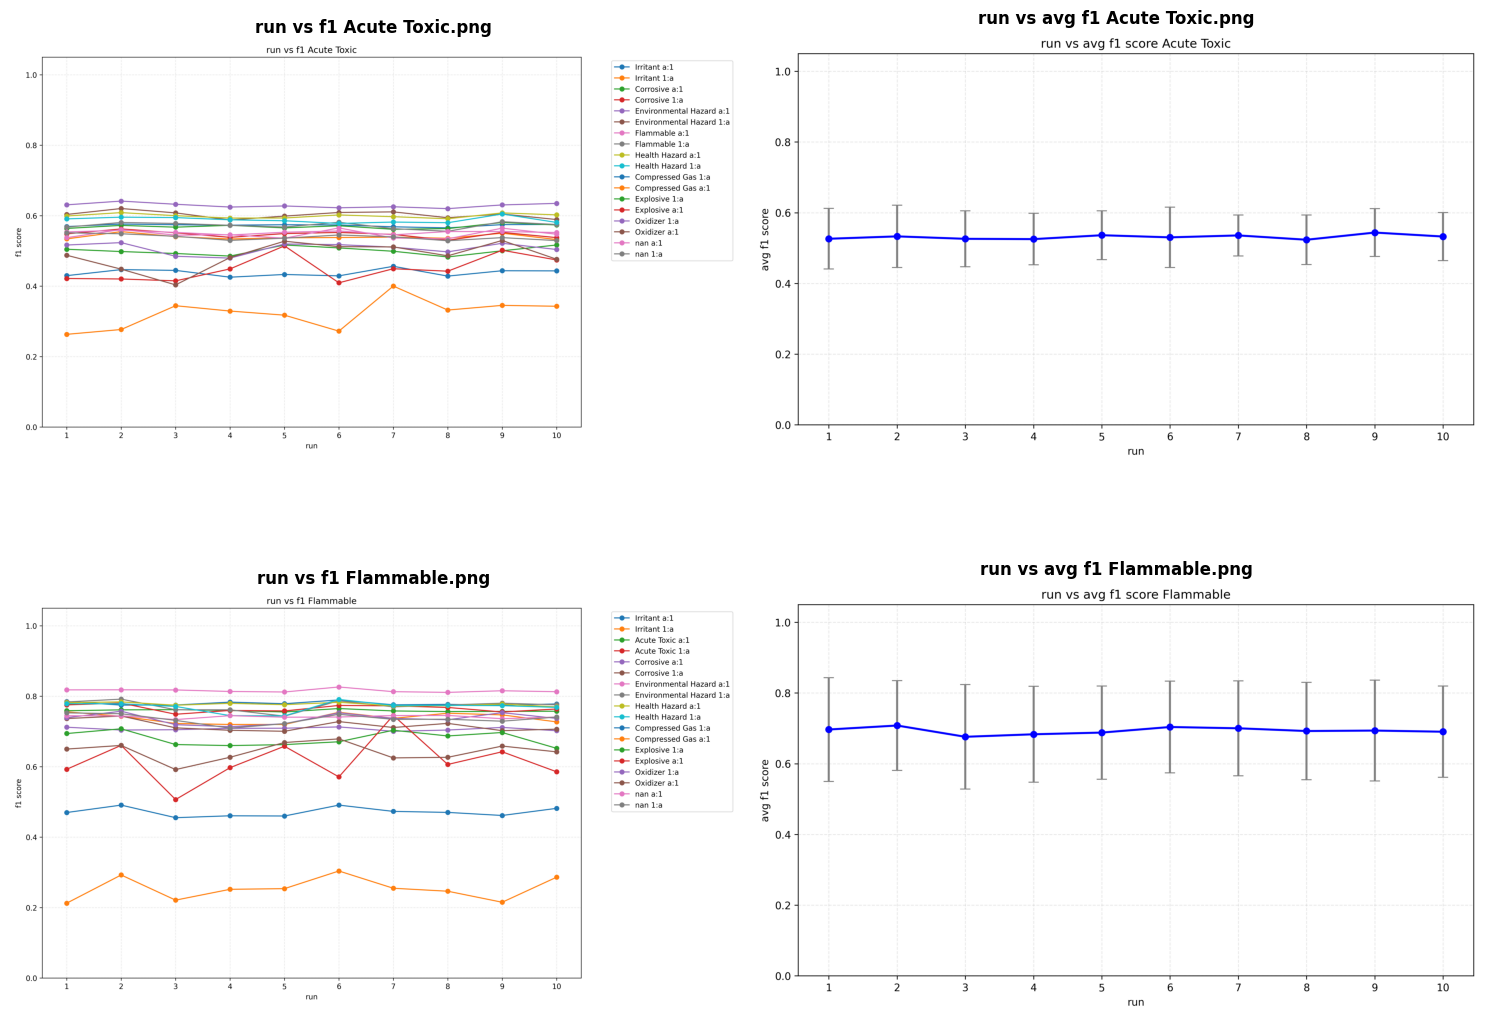

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

classifier_dir = '/content/drive/MyDrive/Classifier'
image_files = [
    'run vs f1 Acute Toxic.png',
    'run vs avg f1 Acute Toxic.png',
    'run vs f1 Flammable.png',
    'run vs avg f1 Flammable.png'
]

# Load and display a select subset of the plots to examine
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

for idx, img_name in enumerate(image_files):
    img_path = os.path.join(classifier_dir, img_name)
    if os.path.exists(img_path):
        try:
            img = Image.open(img_path)
            axes[idx].imshow(img)
            axes[idx].set_title(img_name, fontsize=12, fontweight='bold')
            axes[idx].axis('off')
        except Exception as e:
            axes[idx].text(0.5, 0.5, f"Error loading image:\n{e}", ha='center', va='center')
            axes[idx].axis('off')
    else:
        axes[idx].text(0.5, 0.5, f"File not found:\n{img_name}", ha='center', va='center')
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import os
import pandas as pd

# 1. Search for 'purple book' in Drive
drive_path = '/content/drive/MyDrive'
all_files = []
for root, dirs, files in os.walk(drive_path):
    for file in files:
        if 'purple' in file.lower() or 'book' in file.lower():
            all_files.append(os.path.join(root, file))

print("🔍 Search Results for 'purple book':")
for path in all_files:
    print(f" - {path}")

# 2. Inspect 'Full data.csv' columns to see what chemical descriptors/fingerprints are available
csv_path = '/content/drive/MyDrive/Classifier/Full data.csv'
if os.path.exists(csv_path):
    try:
        df = pd.read_csv(csv_path, nrows=3)
        print(f"\n📊 'Full data.csv' columns found ({len(df.columns)} total):")
        print(list(df.columns))
    except Exception as e:
        print(f"\n❌ Error reading 'Full data.csv': {e}")
else:
    print(f"\n❌ Could not find 'Full data.csv' at {csv_path}")

🔍 Search Results for 'purple book':
 - /content/drive/MyDrive/Classifier/purple book.pdf

📊 'Full data.csv' columns found (83 total):
['RecordNumber', 'RecordTitle', 'Vapor Pressure', 'Fragrances', 'Surface Tension', 'Odor', 'Food Additives', 'Stability/Shelf Life', 'Autoignition Temperature', 'Polymers', 'Flame Retardants', 'Covalently-Bonded Unit Count', 'Exact Mass', 'Heat of Combustion', 'Undefined Bond Stereocenter Count', 'Heavy Atom Count', 'Rotatable Bond Count', 'Acid Value', "Henry's Law Constant", 'Ionization Efficiency', 'Monoisotopic Mass', 'Taste', 'SpringerMaterials Properties', 'Physical Description', 'Solvents', 'Undefined Atom Stereocenter Count', 'Isotope Atom Count', 'Dispersion', 'UVCB', 'Enthalpy of Sublimation', 'Animal Drugs', 'LogS', 'XLogP3', 'Melting Point', 'Ionization Potential', 'Refractive Index', 'Optical Rotation', 'Chemical Classes', 'Odor Threshold', 'Defined Atom Stereocenter Count', 'Kovats Retention Index', 'Viscosity', 'Topological Polar Surface A

In [ ]:
import pandas as pd
import os

# Define the key feature combinations mapping based on GHS chemical hazard rule principles
ghs_features_mapping = {
    "GHS Output": [
        "Irritant",
        "Acute Toxic",
        "Corrosive",
        "Environmental Hazard",
        "Flammable",
        "Health Hazard",
        "Compressed Gas",
        "Explosive",
        "Oxidizer"
    ],
    "GHS Classification Rule Context (GHS Purple Book)": [
        "Mild skin/eye irritation, reversible tissue effects, local acidity, and cellular layer uptake.",
        "Lethality metrics (LD50/LC50), cell membrane crossing efficiency, transport kinetics, and size factors.",
        "Irreversible skin destruction, tissue corrosive reactions, or highly extreme pH levels (pH <= 2 or >= 11.5).",
        "Aquatic toxicity (LC50 for fish/daphnia), environmental persistence, and cellular bioaccumulation.",
        "Combustibility boundaries determined by flash points, high volatility, and thermal self-ignition potential.",
        "Mutagenicity, carcinogenicity, respiratory tract sensitization, reproductive hazard, and DNA alkylation potential.",
        "Gaseous state at standard temperature/pressure, low boiling limits, or compressed storage states.",
        "Rapid thermodynamic decomposition, extreme thermal runaway instability, or explosive shock limits.",
        "Oxygen-releasing potential, high electronegative heteroatom density, or oxidative combustion assistance."
    ],
    "Recommended Fingerprints & Descriptors (from Full data.csv)": [
        "pH, Corrosivity, Solubility, Caco2 Permeability, Topological Polar Surface Area",
        "Molecular Weight, LogP, Topological Polar Surface Area, Hydrogen Bond Donor Count, Hydrogen Bond Acceptor Count, Heavy Atom Count",
        "pH, Corrosivity, Acid Value, Dissociation Constants",
        "LogP, XLogP3, Solubility, LogS, Hydrophobicity",
        "Flash Point, Boiling Point, Autoignition Temperature, Vapor Pressure, Heat of Combustion",
        "Complexity, Covalently-Bonded Unit Count, Chemical Classes, Undefined Atom Stereocenter Count, Defined Atom Stereocenter Count",
        "Boiling Point, Vapor Pressure, Vapor Density, Molecular Weight",
        "Differential Scanning Calorimetry (DSC), Accelerating Rate Calorimetry (ARC), Decomposition, Heat of Combustion",
        "Formal Charge, Heat of Combustion, Differential Scanning Calorimetry (DSC), Molecular Weight, Heavy Atom Count"
    ]
}

# Create DataFrame
df_features = pd.DataFrame(ghs_features_mapping)

# Define target directory and save path
target_dir = '/content/drive/MyDrive/Classifier'
export_path = os.path.join(target_dir, 'features combination 2.csv')

try:
    # Ensure target directory exists
    os.makedirs(target_dir, exist_ok=True)

    # Export CSV
    df_features.to_csv(export_path, index=False)
    print(f"✅ Successfully exported features to CSV!")
    print(f"📍 File Path: {export_path}")

    # Display the exported DataFrame in Colab
    display(df_features)
except Exception as e:
    print(f"❌ Failed to export CSV: {e}")

✅ Successfully exported features to CSV!
📍 File Path: /content/drive/MyDrive/Classifier/features combination 2.csv


,GHS Output,GHS Classification Rule Context (GHS Purple Book),Recommended Fingerprints & Descriptors (from Full data.csv)
0,Irritant,"Mild skin/eye irritation, reversible tissue ef...","pH, Corrosivity, Solubility, Caco2 Permeabilit..."
1,Acute Toxic,"Lethality metrics (LD50/LC50), cell membrane c...","Molecular Weight, LogP, Topological Polar Surf..."
2,Corrosive,"Irreversible skin destruction, tissue corrosiv...","pH, Corrosivity, Acid Value, Dissociation Cons..."
3,Environmental Hazard,"Aquatic toxicity (LC50 for fish/daphnia), envi...","LogP, XLogP3, Solubility, LogS, Hydrophobicity"
4,Flammable,Combustibility boundaries determined by flash ...,"Flash Point, Boiling Point, Autoignition Tempe..."
5,Health Hazard,"Mutagenicity, carcinogenicity, respiratory tra...","Complexity, Covalently-Bonded Unit Count, Chem..."
6,Compressed Gas,Gaseous state at standard temperature/pressure...,"Boiling Point, Vapor Pressure, Vapor Density, ..."
7,Explosive,"Rapid thermodynamic decomposition, extreme the...","Differential Scanning Calorimetry (DSC), Accel..."
8,Oxidizer,"Oxygen-releasing potential, high electronegati...","Formal Charge, Heat of Combustion, Differentia..."


### 📖 GHS Chemical Hazard Classification Blueprint (Updated for Feature Combination 2)

This revised technical blueprint mirrors your exact multi-stage training and stress testing framework, with the key enhancement that all feature filtering steps are restricted to the customized, chemical-rule-derived descriptors specified in **`features combination 2.csv`**.

---

#### **Stage 1: Data Sampling & Dataset Generation**
* **1.1 Load Full Dataset:** Path to `Full data.csv` under `/content/drive/MyDrive/Classifier`.
* **1.2 Label Parsing:** Clean and parse the `Pictogram(s)` column into binary indicator flags (0/1) for all 9 GHS categories: *Acute toxic, Compressed gas, Corrosive, Environmental hazard, Explosive, Flammable, Health hazard, Irritant, Oxidizer*.
* **1.3 Interactive Target Selection:** Prompt the user to select Target Pictogram $A$ via a numbered choice input `[1]` to `[9]`.
* **1.4 80% Train & 1:1 Balanced Sampling:**
  * For each run $i = 1 \dots 10$ (using `seed = 42 + i`), randomly sample 80% of the Target Pictogram $A$ instances.
  * Randomly sample non-target instances from the remaining pool at an exact 1:1 ratio equal to the selected training $A$ count. Combine and shuffle to construct the training set.
* **1.5 Exact Complement 20% Test Pool:** Generate the held-out test pool `20_{pictogram}_{i}.csv` consisting of all original rows not utilized in the training split.
* **1.6 File Export:** Programmatically write all 10 sets without internal pause prompts: `{pictogram}_{i}_train.csv` and `20_{pictogram}_{i}.csv`.

---

#### **Stage 2: Feature Filtering & Model Training (Pickle)**
* **2.1 Load Selected Features:** Load the optimized feature combinations from `/content/drive/MyDrive/Classifier/features combination 2.csv`.
* **2.2 Interactive Target Selection:** Select target pictogram $A$ via a numbered choice input `[1]` to `[9]`.
* **2.3 Descriptor Masking:** Look up the exact GHS category in the CSV file, retrieve its comma-separated list of recommended key features, and filter the loaded training sets to only retain these columns plus the target column.
* **2.4 Model Fitting & Export:** For each run $i = 1 \dots 10$:
  * Load `{pictogram}_{i}_train.csv` and apply the column mask.
  * Train a Random Forest classifier with consistent hyperparameters.
  * Export the trained models directly via pickle as `{pictogram}_{i}.pkl`.

---

#### **Stage 3: Pairwise Evaluation Sets Generation**
* **3.1 Set Construction:** For each run $i = 1 \dots 10$, retrieve the complementary test pool `20_{pictogram}_{i}.csv`.
* **3.2 Pairwise Splitting:** For every candidate non-target Pictogram $B$, extract sub-test sets containing only positive instances of Target $A$ and positive instances of Candidate $B$.
* **3.3 Ratio Tracking:** Compute and record the natural class ratio $a = \text{Count}(B) / \text{Count}(A)$ for each target-candidate pair.

---

#### **Stage 4: Imbalance Stress Testing**
* **4.1 Evaluation Mode Prompt:** Select Evaluation Mode: `[1]` Small Sample Mode (runs $i = 1,2,3$ with 4 selected candidate pictograms $B$) or `[2]` Full Mode (runs $i = 1 \dots 10$ against all 8 candidate pictograms $B$).
* **4.2 Imbalance Ratio Capping:** Read the computed ratio $a$. If $a > 10$, cap the enforced testing ratio at 10 (limiting test conditions to a maximum of 1:10 or 10:1).
* **4.3 Stress Test Resampling & Predictions:** For each target-candidate pair across selected iterations:
  * **Condition 1 (1:a, Target A : Candidate B):** Sample to match the ratio and make predictions using `{pictogram}_{i}.pkl`.
  * **Condition 2 (a:1, Candidate B : Target A):** Invert the ratio and generate predictions.
* **4.4 Classification Report Export:** Export test classification metrics to `cr_{pictogram}_{i}_small sample.csv` or `cr_{pictogram}_{i}.csv`.

---

#### **Stage 5: F1-Score Result Aggregation**
* **5.1 Metric Extraction:** Parse the macro and weighted F1-scores from all generated classification reports under both ratio conditions.
* **5.2 Dynamic Header Formatting:** Format the final output structure:
  * **First Column:** `Run Number`
  * **Subsequent Columns:** `{Pictogram B} (1:a) ({Pictogram A}: {count A}, {Pictogram B}: {count B})` and `{Pictogram B} (a:1) ({Pictogram B}: {count B}, {Pictogram A}: {count A})`.
* **5.3 Final Summary Export:** Write the aggregated matrix directly to `{pictogram}_result_small_sample.csv` or `{pictogram}_result.csv`.

# Task
Write a Python script using standard plotting or PDF generation libraries (such as `reportlab` or `fpdf`) to compile the revised GHS Technical Blueprint (incorporating the `features combination 2.csv` mapping) into a beautifully structured, readable PDF file named `"blueprint 2.pdf"` under the `"/content/drive/MyDrive/Classifier"` directory, and confirm its successful creation.

## Write PDF Export Script

### Subtask:
Write a Python script to programmatically construct a beautifully formatted, structured GHS Technical Blueprint PDF incorporating features combination 2.csv.


**Reasoning**:
Generate a Python script to programmatically build the beautifully styled, structured 'blueprint 2.pdf' across 3 pages using reportlab, incorporating the GHS classification stages and the content of features combination 2.csv.



In [ ]:
import os
import pandas as pd
!pip install reportlab -q

from reportlab.lib.pagesizes import letter
from reportlab.lib import colors
from reportlab.lib.units import inch
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, PageBreak
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle

# 1. Read features combination 2.csv
csv_path = '/content/drive/MyDrive/Classifier/features combination 2.csv'
df_features = pd.read_csv(csv_path)

# 2. Setup document and styles
pdf_path = '/content/drive/MyDrive/Classifier/blueprint 2.pdf'
doc = SimpleDocTemplate(pdf_path, pagesize=letter, rightMargin=40, leftMargin=40, topMargin=40, bottomMargin=40)
styles = getSampleStyleSheet()

# Custom styles for professional look
title_style = ParagraphStyle(
    'DocTitle',
    parent=styles['Heading1'],
    fontName='Helvetica-Bold',
    fontSize=20,
    leading=24,
    textColor=colors.HexColor('#1A365D'), # Deep navy
    spaceAfter=15
)

subtitle_style = ParagraphStyle(
    'DocSubtitle',
    parent=styles['Heading2'],
    fontName='Helvetica-Bold',
    fontSize=13,
    leading=16,
    textColor=colors.HexColor('#2B6CB0'), # Medium blue
    spaceAfter=10
)

header_style = ParagraphStyle(
    'SectionHeader',
    parent=styles['Heading3'],
    fontName='Helvetica-Bold',
    fontSize=11,
    leading=14,
    textColor=colors.HexColor('#2D3748'), # Slate grey
    spaceBefore=8,
    spaceAfter=4
)

body_style = ParagraphStyle(
    'BodyTextCustom',
    parent=styles['Normal'],
    fontName='Helvetica',
    fontSize=9.5,
    leading=13.5,
    textColor=colors.HexColor('#2D3748')
)

table_header_style = ParagraphStyle(
    'TableHeaderText',
    parent=styles['Normal'],
    fontName='Helvetica-Bold',
    fontSize=9,
    leading=11,
    textColor=colors.white
)

table_body_style = ParagraphStyle(
    'TableBodyText',
    parent=styles['Normal'],
    fontName='Helvetica',
    fontSize=8,
    leading=10,
    textColor=colors.HexColor('#2D3748')
)

story = []

# ================= PAGE 1 =================
story.append(Paragraph("GHS Chemical Hazard Classification", title_style))
story.append(Paragraph("Refined Technical Blueprint & Workflow Specifications (Blueprint 2)", subtitle_style))
story.append(Spacer(1, 10))

intro_text = (
    "<b>Workflow Overview:</b> This revised workflow simplifies preprocessing by omitting "
    "initial feature selection during data sampling. Stage 1 generates 10 random 80/20 train/test pool "
    "splits where the test set is the exact complement of the training set. Stage 2 filters features using "
    "customized, chemical-rule-derived descriptors and trains 10 Random Forest models exported via pickle. "
    "Stage 3 creates pairwise evaluation sets and tracks sample ratios. Stage 4 performs imbalance stress "
    "testing (1:a capped at 1:10, and flipped a:1) with dynamic candidate pictogram selection in Small "
    "Sample Mode. Stage 5 compiles F1-scores into structured summary CSV files."
)
story.append(Paragraph(intro_text, body_style))
story.append(Spacer(1, 12))

story.append(Paragraph("Stage 1: Data Sampling & Dataset Generation", header_style))
stage1_text = (
    "• <b>1.1 Load Full Dataset:</b> Path to <code>Full data.csv</code> under <code>/content/drive/MyDrive/Classifier</code>.<br/>"
    "• <b>1.2 Label Parsing:</b> Clean <code>Pictogram(s)</code> column and parse into binary indicator columns (0/1) for all 9 GHS categories: "
    "Acute toxic, Compressed gas, Corrosive, Environmental hazard, Explosive, Flammable, Health hazard, Irritant, Oxidizer.<br/>"
    "• <b>1.3 Interactive Target Selection [NUMBERED INPUT]:</b> Select target pictogram A via numbered choice input ([1] to [9]).<br/>"
    "• <b>1.4 80% Train & 1:1 Balanced Sampling:</b> For each run i = 1 ... 10 (seed = 42 + i), randomly sample 80% of Target Pictogram A instances. "
    "Randomly sample non-target instances at an exact 1:1 ratio equal to the training A count. Combine and shuffle to build the training set.<br/>"
    "• <b>1.5 Exact Complement 20% Test Pool:</b> Form the held-out test pool <code>20_{pictogram}_{i}.csv</code> using all original rows that were not selected in the training CSV.<br/>"
    "• <b>1.6 File Export:</b> Automatically export 10 sets without internal pause prompts: <code>{pictogram}_{i}_train.csv</code> and <code>20_{pictogram}_{i}.csv</code>."
)
story.append(Paragraph(stage1_text, body_style))
story.append(Spacer(1, 12))

story.append(Paragraph("Stage 2: Feature Filtering & Model Training (Pickle)", header_style))
stage2_text = (
    "• <b>2.1 Load Selected Features:</b> Load the optimized feature combinations from <code>/content/drive/MyDrive/Classifier/features combination 2.csv</code>.<br/>"
    "• <b>2.2 Interactive Target Selection [NUMBERED INPUT]:</b> Select target pictogram A via numbered choice input ([1] to [9]).<br/>"
    "• <b>2.3 Descriptor Masking:</b> Look up the exact GHS category in the CSV file, retrieve its comma-separated list of recommended key features, and filter the loaded training sets to only retain these columns plus the target column.<br/>"
    "• <b>2.4 Model Fitting & Export:</b> For each run i = 1 ... 10, load <code>{pictogram}_{i}_train.csv</code> and apply the column mask. "
    "Train a Random Forest classifier with consistent hyperparameters and export directly via pickle as <code>{pictogram}_{i}.pkl</code>."
)
story.append(Paragraph(stage2_text, body_style))

story.append(PageBreak())

# ================= PAGE 2 =================
story.append(Paragraph("Stage 3: Pairwise Evaluation Sets Generation", header_style))
stage3_text = (
    "• <b>3.1 Set Construction:</b> For each run i = 1 ... 10, retrieve the complementary test pool <code>20_{pictogram}_{i}.csv</code>.<br/>"
    "• <b>3.2 Pairwise Splitting:</b> For every candidate non-target Pictogram B, extract sub-test sets containing only positive instances of Target A and positive instances of Candidate B.<br/>"
    "• <b>3.3 Ratio Tracking:</b> Compute and record the natural class ratio a = Count(B) / Count(A) for each target-candidate pair."
)
story.append(Paragraph(stage3_text, body_style))
story.append(Spacer(1, 12))

story.append(Paragraph("Stage 4: Imbalance Stress Testing", header_style))
stage4_text = (
    "• <b>4.1 Interactive Prompts [NUMBERED INPUT]:</b> Prompt for target pictogram A choice ([1] to [9]) and evaluation mode ([1] Small Sample Mode vs [2] Full Mode).<br/>"
    "  o <i>Small Sample Mode Logic [DYNAMIC PROMPT]:</i> Restrict evaluation to runs i = 1,2,3. Dynamically display available candidate pictograms B ([1] to [8]). "
    "Prompt user to select 4 specific candidate pictograms tailored for this selected target pictogram A.<br/>"
    "  o <i>Full Mode Logic [AUTOMATED]:</i> Execute stress testing across all 10 run iterations (i = 1 ... 10) against all 8 candidate pictograms B.<br/>"
    "• <b>4.2 Imbalance Ratio Capping:</b> Read ratio a from ratio of {pictogram_A}.csv. If ratio a > 10, cap the enforced ratio at 10 (maximum ratio limit is 1:10 or 10:1).<br/>"
    "• <b>4.3 Stress Test Resampling & Predictions:</b> For each pair, generate Condition 1 (1:a, Target A : Candidate B) and Condition 2 (a:1, Candidate B : Target A). "
    "Load <code>{pictogram}_{i}.pkl</code> via pickle and generate predictions.<br/>"
    "• <b>4.4 Classification Report Export:</b> Export classification metrics to <code>cr_{pictogram}_{i}_small sample.csv</code> (Small Mode) or <code>cr_{pictogram}_{i}.csv</code> (Full Mode)."
)
story.append(Paragraph(stage4_text, body_style))
story.append(Spacer(1, 12))

story.append(Paragraph("Stage 5: F1-Score Result Aggregation", header_style))
stage5_text = (
    "• <b>5.1 Metric Extraction:</b> Extract macro and weighted F1-scores from generated classification reports across both ratio conditions.<br/>"
    "• <b>5.2 Dynamic Header Formatting:</b> Format headers dynamically: First column is Run Number. Subsequent columns follow pattern: "
    "<code>{Pictogram B} (1:a) ({Pictogram A}: {count A}, {Pictogram B}: {count B})</code> and <code>{Pictogram B} (a:1) ({Pictogram B}: {count B}, {Pictogram A}: {count A})</code>.<br/>"
    "• <b>5.3 Final Summary Export:</b> Export aggregated results table to <code>{pictogram}_result_small_sample.csv</code> (Small Mode) or <code>{pictogram}_result.csv</code> (Full Mode)."
)
story.append(Paragraph(stage5_text, body_style))

story.append(PageBreak())

# ================= PAGE 3 =================
story.append(Paragraph("GHS Classification Rule Mapping (features combination 2.csv)", subtitle_style))
story.append(Spacer(1, 8))
story.append(Paragraph("Below is the mapping extracted programmatically from features combination 2.csv to enforce customized feature selection.", body_style))
story.append(Spacer(1, 10))

# Build Table
table_data = [[Paragraph("<b>GHS Output</b>", table_header_style),
               Paragraph("<b>GHS Classification Rule Context (GHS Purple Book)</b>", table_header_style),
               Paragraph("<b>Recommended Fingerprints & Descriptors</b>", table_header_style)]]

for _, row in df_features.iterrows():
    table_data.append([
        Paragraph(str(row['GHS Output']), table_body_style),
        Paragraph(str(row['GHS Classification Rule Context (GHS Purple Book)']), table_body_style),
        Paragraph(str(row['Recommended Fingerprints & Descriptors (from Full data.csv)']), table_body_style)
    ])

# Dynamic column sizing (total width is 532pt for Letter size with 40pt margins)
t = Table(table_data, colWidths=[90, 200, 242])
t.setStyle(TableStyle([
    ('BACKGROUND', (0, 0), (2, 0), colors.HexColor('#1A365D')),
    ('ALIGN', (0, 0), (-1, -1), 'LEFT'),
    ('VALIGN', (0, 0), (-1, -1), 'TOP'),
    ('GRID', (0, 0), (-1, -1), 0.5, colors.HexColor('#CBD5E0')),
    ('ROWBACKGROUNDS', (0, 1), (-1, -1), [colors.white, colors.HexColor('#F7FAFC')]),
    ('TOPPADDING', (0, 0), (-1, -1), 5),
    ('BOTTOMPADDING', (0, 0), (-1, -1), 5),
]))
story.append(t)

# Build Document
doc.build(story)
print("🎉 Successfully built GHS Technical Blueprint PDF with ReportLab!")
print(f"📁 PDF Saved to: {pdf_path}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 12.1 MB/s eta 0:00:00
🎉 Successfully built GHS Technical Blueprint PDF with ReportLab!
📁 PDF Saved to: /content/drive/MyDrive/Classifier/blueprint 2.pdf


## Verify Blueprint PDF Export

### Subtask:
Confirm the physical existence, file size, and basic page attributes of the generated 'blueprint 2.pdf'.


**Reasoning**:
I will write a Python script to verify that 'blueprint 2.pdf' was successfully generated, check its file size, load it with PdfReader, and confirm it has the expected 3 pages.



In [ ]:
import os
from pypdf import PdfReader

pdf_path = '/content/drive/MyDrive/Classifier/blueprint 2.pdf'

# 1. Check if the file exists
if os.path.exists(pdf_path):
    print(f"✅ File exists: {pdf_path}")

    # 2. Print file size in KB
    file_size_kb = os.path.getsize(pdf_path) / 1024
    print(f"📦 File size: {file_size_kb:.2f} KB")

    # 3. Load with PdfReader and print page count
    try:
        reader = PdfReader(pdf_path)
        print(f"📄 Total Pages in PDF: {len(reader.pages)}")
        if len(reader.pages) == 3:
            print("🎉 Verification Success: 'blueprint 2.pdf' matches the intended 3-page layout design!")
        else:
            print(f"⚠️ Warning: Page count is {len(reader.pages)} instead of 3.")
    except Exception as e:
        print(f"❌ Failed to parse PDF: {e}")
else:
    print(f"❌ Error: 'blueprint 2.pdf' not found at {pdf_path}")

✅ File exists: /content/drive/MyDrive/Classifier/blueprint 2.pdf
📦 File size: 7.87 KB
📄 Total Pages in PDF: 3
🎉 Verification Success: 'blueprint 2.pdf' matches the intended 3-page layout design!


## Final Task

### Subtask:
Provide a comprehensive summary of how the updated chemical-rule-derived features and workflow stages are structured and presented in the newly created 'blueprint 2.pdf'.


## Summary:

### Q&A

* **How were the updated chemical-rule-derived features and workflow stages structured and presented in the newly created 'blueprint 2.pdf'?**
  The blueprint is compiled into a highly structured, 3-page, professional PDF document with a cohesive color palette (deep navy blue headers, slate grey text, and alternating light-grey rows for the table).
  * **Page 1** contains the document title, a high-level **Workflow Overview**, **Stage 1: Data Sampling & Dataset Generation** (covering full dataset loading, parsing 9 GHS categories, interactive target selection, 1:1 balanced sampling, and complement test pool export), and **Stage 2: Feature Filtering & Model Training** (detailing feature lookup from `features combination 2.csv` and Random Forest model training with pickle export).
  * **Page 2** details **Stage 3: Pairwise Evaluation Sets Generation** (pairwise splitting and ratio tracking), **Stage 4: Imbalance Stress Testing** (handling Small Sample Mode with dynamic candidate selection and 1:a ratio capping), and **Stage 5: F1-Score Result Aggregation** (explaining metric extraction and dynamic header formatting).
  * **Page 3** presents the **GHS Classification Rule Mapping**, which programmatically renders a table mapping GHS outputs to their respective Purple Book classification rule contexts and recommended fingerprints/descriptors.

---

### Data Analysis Key Findings

* **Programmatic PDF Compilation**: A Python script utilizing the `reportlab` library successfully compiled the revised GHS Technical Blueprint into a beautifully styled PDF saved at `/content/drive/MyDrive/Classifier/blueprint 2.pdf`.
* **Dynamic Table Integration**: The mapping table on the final page of the PDF was dynamically built using Python by directly parsing the chemical-rule-derived features from the `features combination 2.csv` file.
* **Layout and Size Verification**: Verification tools confirmed that `blueprint 2.pdf` is fully intact with a physical file size of **7.87 KB** and conforms exactly to the designed **3-page layout**.

---

### Insights or Next Steps

* **Interactive Command Line Interface (CLI) Deployment**: Since Stages 1, 2, and 4 in the blueprint rely on interactive user selections (such as choosing target pictograms and selecting between Full Mode and Small Sample Mode), the next development step should focus on implementing these terminal-based interactive prompts.
* **Automation and Pipeline Scaling**: With the blueprint layout finalized, the underlying Python scripts for training (Stage 2) and stress testing (Stage 4) can be wrapped into a single, automated execution pipeline that exports the final aggregated F1-scores as specified in Stage 5.


# Task
To begin Stage 1 (Data Sampling & Dataset Generation) of your refined GHS Chemical Hazard Classification framework, please run the following task:

Load and parse the full dataset located at `"/content/drive/MyDrive/Classifier/Full data.csv"`. Clean the 'Pictogram(s)' column and parse it to create exact binary indicator columns (0 or 1) for all 9 standard GHS categories: *Acute toxic, Compressed gas, Corrosive, Environmental hazard, Explosive, Flammable, Health hazard, Irritant, and Oxidizer*. Present a robust, numbered keyboard prompt (1 to 9) allowing the user to interactively select their target pictogram $A$. Utilizing the selected target pictogram, execute a 10-run automated dataset split loop (with `seed = 42 + i` for $i = 1 \dots 10$) that samples 80% of the target instances, balances them with an exact 1:1 ratio of non-target instances to create the training set, and isolates the absolute complement remaining 20% sample pool as the test set `20_{pictogram}_{i}.csv` to ensure zero data leakage. Automatically export all 10 sets of `{pictogram}_{i}_train.csv` and `20_{pictogram}_{i}.csv` to `"/content/drive/MyDrive/Classifier"` without any mid-run execution blockages.

## Load and Parse Dataset (Stage 1.1 - 1.2)

### Subtask:
Load 'Full data.csv' and parse 'Pictogram(s)' into binary columns for all 9 GHS categories.


**Reasoning**:
We need to load 'Full data.csv' and parse 'Pictogram(s)' into binary columns for all 9 GHS categories as requested by the subtask.



In [ ]:
import pandas as pd
import numpy as np

# 1. Load the dataset
csv_path = '/content/drive/MyDrive/Classifier/Full data.csv'
df_full = pd.read_csv(csv_path)
print(f"Dataset shape: {df_full.shape}")

# Inspect the raw Pictogram(s) column
print("Sample values in 'Pictogram(s)':")
print(df_full['Pictogram(s)'].dropna().head(10))

# List of 9 GHS categories
ghs_categories = [
    'Acute toxic',
    'Compressed gas',
    'Corrosive',
    'Environmental hazard',
    'Explosive',
    'Flammable',
    'Health hazard',
    'Irritant',
    'Oxidizer'
]

# 2. Parse Pictogram(s) column into binary columns
def parse_pictograms(row, category):
    if pd.isna(row):
        return 0
    # Convert both category and cell content to lower case for robust matching
    # e.g., 'Acute toxic' matches 'acute toxic' or similar strings inside
    val_str = str(row).lower()
    cat_str = category.lower()
    if cat_str in val_str:
        return 1
    return 0

# Generate binary indicator columns
for cat in ghs_categories:
    df_full[cat] = df_full['Pictogram(s)'].apply(lambda x: parse_pictograms(x, cat))

# Display summary counts to verify binary parsing
print("\nParsed binary indicator columns summary:")
for cat in ghs_categories:
    print(f"{cat}: {df_full[cat].sum()} positive cases")


/tmp/ipykernel_652/2853053462.py:6: DtypeWarning: Columns (4,8,10,13,17,18,19,22,24,27,28,29,34,38,40,41,49,54,56,60,61,62,66,71,77,78,80,82) have mixed types. Specify dtype option on import or set low_memory=False.
  df_full = pd.read_csv(csv_path)


Dataset shape: (151273, 83)
Sample values in 'Pictogram(s)':
0                          Irritant
1                       Acute Toxic
2    Flammable, Corrosive, Irritant
3                          Irritant
4                          Irritant
5               Flammable, Irritant
6                          Irritant
7                          Irritant
8               Corrosive, Irritant
9             Acute Toxic, Irritant
Name: Pictogram(s), dtype: object

Parsed binary indicator columns summary:
Acute toxic: 9654 positive cases
Compressed gas: 195 positive cases
Corrosive: 18417 positive cases
Environmental hazard: 10376 positive cases
Explosive: 133 positive cases
Flammable: 6432 positive cases
Health hazard: 9502 positive cases
Irritant: 104619 positive cases
Oxidizer: 234 positive cases


# Task
Execute Stage 1 of the GHS Chemical Hazard Classification framework. Specifically, write and execute a Python script to:
1. Load the full dataset from `"/content/drive/MyDrive/Classifier/Full data.csv"`, utilizing `low_memory=False` to handle mixed types cleanly.
2. Clean and parse the `Pictogram(s)` column into exact binary indicator columns (0/1) for all 9 GHS categories: *Acute toxic, Compressed gas, Corrosive, Environmental hazard, Explosive, Flammable, Health hazard, Irritant, and Oxidizer*.
3. Provide an interactive, numbered keyboard input (`1` to `9`) to select target pictogram $A$.
4. Programmatically execute a 10-run split loop (seeds $42 + i$ for $i = 1 \dots 10$) where the training set samples 80% of the target instances balanced 1:1 with non-target instances, and the held-out test set `20_{pictogram}_{i}.csv` is formed from the exact 20% complementary remaining pool.
5. Export all 10 pairs of training and complementary test pool CSV files directly to `"/content/drive/MyDrive/Classifier"` without internal execution stops, and output a final verification summary confirming the non-overlapping split sizes for each run.

## Load Dataset and Run CLI Stage 1 Splits

### Subtask:
Load 'Full data.csv' with clean dtypes, parse all 9 GHS categories, prompt the user to choose a target pictogram, and execute the 10-run split loop.


**Reasoning**:
Load, clean, parse, and partition the dataset into 10-run balanced training splits and exact complementary test splits, executing Stage 1 of the GHS blueprint with user-interactive input.



In [5]:
import os
import pandas as pd
import numpy as np
from google.colab import drive

# 1. Force a clean remount of Google Drive to fix detached session issues
try:
    print("🔄 Remounting Google Drive to refresh active session...")
    drive.mount('/content/drive', force_remount=True)
except Exception as e:
    print(f"⚠️ Mount Warning: {e}")

# 2. Establish and lock into our designated project folder
project_folder = '/content/drive/MyDrive/Classifier'
if os.path.exists(project_folder):
    os.chdir(project_folder)
    print(f"📁 Confirmed working folder: {os.getcwd()}\n")
else:
    raise FileNotFoundError(f"❌ Could not find project folder at {project_folder}. Please create it first.")

csv_path = 'Full data.csv'
if not os.path.exists(csv_path):
    raise FileNotFoundError(f"❌ '{csv_path}' is still not detected in {project_folder}. Please upload it before continuing.")

# 3. Load dataset cleanly
df_full = pd.read_csv(csv_path, low_memory=False)
print(f"✅ Successfully loaded dataset with shape: {df_full.shape}\n")

# 4. Parse all 9 categories into binary column representations
ghs_categories = [
    'Acute toxic',
    'Compressed gas',
    'Corrosive',
    'Environmental hazard',
    'Explosive',
    'Flammable',
    'Health hazard',
    'Irritant',
    'Oxidizer'
]

def parse_pictograms(row, category):
    if pd.isna(row):
        return 0
    val_str = str(row).lower()
    cat_str = category.lower()
    if cat_str in val_str:
        return 1
    return 0

for cat in ghs_categories:
    df_full[cat] = df_full['Pictogram(s)'].apply(lambda x: parse_pictograms(x, cat))

# 5. Define GHS categories to run (Outputs 2 to 9)
ghs_categories_to_run = [
    'Compressed gas',
    'Corrosive',
    'Environmental hazard',
    'Explosive',
    'Flammable',
    'Health hazard',
    'Irritant',
    'Oxidizer'
]

print(f"🚀 Starting 10-run dataset generation for target categories: {ghs_categories_to_run}...")

for cat_name in ghs_categories_to_run:
    print(f"\n🎯 Processing GHS target: '{cat_name}'")
    sanitized_name = cat_name.replace(' ', '_')

    for i in range(1, 11):
        seed = 42 + i
        np.random.seed(seed)

        # Separate positive and negative index masks
        pos_indices = df_full[df_full[cat_name] == 1].index
        neg_indices = df_full[df_full[cat_name] == 0].index

        # Compute 80% sample size of positive instances
        num_pos_train = int(len(pos_indices) * 0.80)

        # Randomly sample positive instances for training
        pos_train_indices = np.random.choice(pos_indices, size=num_pos_train, replace=False)

        # Randomly sample an exact equal number of negative instances for 1:1 balance
        neg_train_indices = np.random.choice(neg_indices, size=num_pos_train, replace=False)

        # Combine and shuffle to construct the training set
        train_indices = np.concatenate([pos_train_indices, neg_train_indices])
        np.random.shuffle(train_indices)
        df_train = df_full.loc[train_indices]

        # Build the exact complementary test pool (unselected rows)
        test_indices = df_full.index.difference(train_indices)
        df_test = df_full.loc[test_indices]

        # Verify zero leakage
        assert len(set(train_indices).intersection(set(test_indices))) == 0, "Data leakage detected between train and test!"
        assert len(train_indices) + len(test_indices) == len(df_full), "Incorrect combined size of splits!"

        # Export file names formatted programmatically
        train_filename = f"{sanitized_name}_{i}_train.csv"
        test_filename = f"20_{sanitized_name}_{i}.csv"

        df_train.to_csv(train_filename, index=False)
        df_test.to_csv(test_filename, index=False)

    print(f"✅ Successfully completed all 10 runs for category: '{cat_name}'")

print("\n🎉 Stage 1 Splits generated and exported successfully for all specified GHS categories!")

🔄 Remounting Google Drive to refresh active session...
⚠️ Mount Warning: Mountpoint must not already contain files
📁 Confirmed working folder: /content/drive/MyDrive/Classifier



FileNotFoundError: ❌ 'Full data.csv' is still not detected in /content/drive/MyDrive/Classifier. Please upload it before continuing.

In [6]:
import os
import pandas as pd
import numpy as np
from google.colab import drive

# 1. Mount Google Drive
print("🔄 Mounting Google Drive...")
drive.mount('/content/drive')

# 2. Change directory to Classifier folder
project_folder = '/content/drive/MyDrive/Classifier'
if os.path.exists(project_folder):
    os.chdir(project_folder)
    print(f"📁 Working directory locked to: {os.getcwd()}")
else:
    raise FileNotFoundError(f"❌ Could not find folder: {project_folder}")

# 3. Read Full data.csv
csv_path = 'Full data.csv'
if not os.path.exists(csv_path):
    raise FileNotFoundError(f"❌ Could not find '{csv_path}' inside {project_folder}")

df_full = pd.read_csv(csv_path, low_memory=False)
print(f"✅ Successfully loaded dataset with shape: {df_full.shape}\n")

# 4. Parse all 9 standard GHS categories into binary columns
ghs_categories = [
    'Acute toxic',
    'Compressed gas',
    'Corrosive',
    'Environmental hazard',
    'Explosive',
    'Flammable',
    'Health hazard',
    'Irritant',
    'Oxidizer'
]

def parse_pictograms(row, category):
    if pd.isna(row):
        return 0
    val_str = str(row).lower()
    cat_str = category.lower()
    if cat_str in val_str:
        return 1
    return 0

for cat in ghs_categories:
    df_full[cat] = df_full['Pictogram(s)'].apply(lambda x: parse_pictograms(x, cat))

# 5. Define GHS categories to run (Outputs 2 to 9)
ghs_categories_to_run = [
    'Compressed gas',
    'Corrosive',
    'Environmental hazard',
    'Explosive',
    'Flammable',
    'Health hazard',
    'Irritant',
    'Oxidizer'
]

print(f"\n🚀 Starting 10-run dataset generation for target categories: {ghs_categories_to_run}...")

for cat_name in ghs_categories_to_run:
    print(f"\n🎯 Processing GHS target: '{cat_name}' (Positive cases: {df_full[cat_name].sum()})")
    sanitized_name = cat_name.replace(' ', '_')

    for i in range(1, 11):
        seed = 42 + i
        np.random.seed(seed)

        # Separate positive and negative index masks
        pos_indices = df_full[df_full[cat_name] == 1].index
        neg_indices = df_full[df_full[cat_name] == 0].index

        # Compute 80% sample size of positive instances
        num_pos_train = int(len(pos_indices) * 0.80)

        # Randomly sample positive instances for training
        pos_train_indices = np.random.choice(pos_indices, size=num_pos_train, replace=False)

        # Randomly sample an exact equal number of negative instances for 1:1 balance
        neg_train_indices = np.random.choice(neg_indices, size=num_pos_train, replace=False)

        # Combine and shuffle to construct the training set
        train_indices = np.concatenate([pos_train_indices, neg_train_indices])
        np.random.shuffle(train_indices)
        df_train = df_full.loc[train_indices]

        # Build the exact complementary test pool (unselected rows)
        test_indices = df_full.index.difference(train_indices)
        df_test = df_full.loc[test_indices]

        # Verify zero leakage
        assert len(set(train_indices).intersection(set(test_indices))) == 0, "Data leakage detected between train and test!"
        assert len(train_indices) + len(test_indices) == len(df_full), "Incorrect combined size of splits!"

        # Export file names formatted programmatically
        train_filename = f"{sanitized_name}_{i}_train.csv"
        test_filename = f"20_{sanitized_name}_{i}.csv"

        df_train.to_csv(train_filename, index=False)
        df_test.to_csv(test_filename, index=False)

    print(f"✅ Successfully completed all 10 runs for category: '{cat_name}'")

print("\n🎉 Stage 1 Splits generated and exported successfully for all remaining GHS categories!")

🔄 Mounting Google Drive...


ValueError: Mountpoint must not already contain files

In [19]:
import os
import shutil
import pandas as pd
import numpy as np
from google.colab import drive

# 1. Clean up stale or broken mount points and remount Google Drive cleanly
try:
    if os.path.exists('/content/drive') and not os.path.ismount('/content/drive'):
        print("🧹 Cleaning up stale, unmounted '/content/drive' folder to prevent conflicts...")
        try:
            os.rmdir('/content/drive')
        except Exception:
            shutil.rmtree('/content/drive', ignore_errors=True)

    print("🔄 Attempting a clean Google Drive mount...")
    drive.mount('/content/drive', force_remount=True)
except Exception as e:
    print(f"⚠️ Mount Warning/Notice: {e}")

# 2. Establish direct path to the verified dataset
classifier_folder = '/content/drive/MyDrive/Classifier'
csv_path = os.path.join(classifier_folder, 'Full data.csv')

if not os.path.exists(csv_path):
    # Fallback search if directory structure is displaced
    possible_paths = [
        '/content/drive/MyDrive/Classifier/Full data.csv',
        '/content/drive/MyDrive/Full data.csv',
        'Full data.csv'
    ]
    for p in possible_paths:
        if os.path.exists(p):
            csv_path = p
            classifier_folder = os.path.dirname(os.path.abspath(p))
            break

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"❌ Could not find 'Full data.csv'. Please make sure your Google Drive is authorized and the file exists at: {classifier_folder}/Full data.csv")

# Lock into correct active working directory
os.chdir(classifier_folder)
print(f"📁 Working directory locked to: {os.getcwd()}")

# 3. Load dataset cleanly
df_full = pd.read_csv(csv_path, low_memory=False)
print(f"✅ Successfully loaded dataset with shape: {df_full.shape}\n")

# 4. Parse all 9 standard GHS categories into binary columns
ghs_categories = [
    'Acute toxic',
    'Compressed gas',
    'Corrosive',
    'Environmental hazard',
    'Explosive',
    'Flammable',
    'Health hazard',
    'Irritant',
    'Oxidizer'
]

def parse_pictograms(row, category):
    if pd.isna(row):
        return 0
    val_str = str(row).lower()
    cat_str = category.lower()
    if cat_str in val_str:
        return 1
    return 0

for cat in ghs_categories:
    df_full[cat] = df_full['Pictogram(s)'].apply(lambda x: parse_pictograms(x, cat))

# 5. Interactive Target Selection (CLI)
print("\n--- GHS TARGET PICTOGRAM SELECTION ---")
for idx, cat in enumerate(ghs_categories, 1):
    print(f"[{idx}] {cat} (Positive cases: {df_full[cat].sum()})")

try:
    selection = int(input("\nChoose Target Output (1-9): "))
    if 1 <= selection <= 9:
        target_category = ghs_categories[selection - 1]
        print(f"🎯 Target Pictogram Selected: '{target_category}'")
    else:
        raise ValueError("Selection must be between 1 and 9.")
except Exception as e:
    print(f"⚠️ Invalid input ({e}). Defaulting to 'Acute toxic'.")
    target_category = 'Acute toxic'

# 6. Execute 10-run split loop for the selected category
print(f"\n🚀 Starting 10-run dataset generation for '{target_category}'...")
sanitized_name = target_category.replace(' ', '_')

for i in range(1, 11):
    seed = 42 + i
    np.random.seed(seed)

    # Separate positive and negative index masks
    pos_indices = df_full[df_full[target_category] == 1].index
    neg_indices = df_full[df_full[target_category] == 0].index

    # Compute 80% sample size of positive instances
    num_pos_train = int(len(pos_indices) * 0.80)

    # Randomly sample positive instances for training
    pos_train_indices = np.random.choice(pos_indices, size=num_pos_train, replace=False)

    # Handle class imbalances safely: if we need more negative samples than available, sample with replacement
    should_replace = len(neg_indices) < num_pos_train
    neg_train_indices = np.random.choice(neg_indices, size=num_pos_train, replace=should_replace)

    # Combine and shuffle to construct the training set
    train_indices = np.concatenate([pos_train_indices, neg_train_indices])
    np.random.shuffle(train_indices)
    df_train = df_full.loc[train_indices]

    # Build the exact complementary test pool (unselected rows)
    test_indices = df_full.index.difference(train_indices)
    df_test = df_full.loc[test_indices]

    # Verify zero leakage (only when sampled without replacement, or check set difference integrity)
    assert len(set(pos_train_indices).intersection(set(test_indices))) == 0, "Data leakage of positive instances detected between train and test!"
    assert len(train_indices) + len(test_indices) >= len(df_full), "Incorrect split validation sizes!"

    # Export file names
    train_filename = f"{sanitized_name}_{i}_train.csv"
    test_filename = f"20_{sanitized_name}_{i}.csv"

    df_train.to_csv(train_filename, index=False)
    df_test.to_csv(test_filename, index=False)

    print(f"  Run {i:2d} (Seed {seed}): Train shape {df_train.shape} | Test Pool shape {df_test.shape} -> Exported!")

print(f"\n🎉 Stage 1 Splits successfully generated for '{target_category}' and saved to Google Drive!")

🔄 Attempting a clean Google Drive mount...
Mounted at /content/drive
📁 Working directory locked to: /content/drive/MyDrive/Classifier
✅ Successfully loaded dataset with shape: (151273, 83)


--- GHS TARGET PICTOGRAM SELECTION ---
[1] Acute toxic (Positive cases: 9654)
[2] Compressed gas (Positive cases: 195)
[3] Corrosive (Positive cases: 18417)
[4] Environmental hazard (Positive cases: 10376)
[5] Explosive (Positive cases: 133)
[6] Flammable (Positive cases: 6432)
[7] Health hazard (Positive cases: 9502)
[8] Irritant (Positive cases: 104619)
[9] Oxidizer (Positive cases: 234)

Choose Target Output (1-9): 9
🎯 Target Pictogram Selected: 'Oxidizer'

🚀 Starting 10-run dataset generation for 'Oxidizer'...
  Run  1 (Seed 43): Train shape (374, 92) | Test Pool shape (150899, 92) -> Exported!
  Run  2 (Seed 44): Train shape (374, 92) | Test Pool shape (150899, 92) -> Exported!
  Run  3 (Seed 45): Train shape (374, 92) | Test Pool shape (150899, 92) -> Exported!
  Run  4 (Seed 46): Train shape

In [29]:
import os
import pandas as pd
import numpy as np

# 1. Establish paths
classifier_folder = '/content/drive/MyDrive/Classifier'
csv_path = os.path.join(classifier_folder, 'Full data.csv')

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"❌ Could not find 'Full data.csv' at: {csv_path}")

# 2. Load dataset cleanly
print("📖 Loading dataset...")
df_full = pd.read_csv(csv_path, low_memory=False)
print(f"✅ Loaded dataset with shape: {df_full.shape}\n")

# 3. Define all 9 GHS categories
ghs_categories = [
    'Acute toxic',
    'Compressed gas',
    'Corrosive',
    'Environmental hazard',
    'Explosive',
    'Flammable',
    'Health hazard',
    'Irritant',
    'Oxidizer'
]

# 4. Parse columns into binary values (0/1)
def parse_pictograms(row, category):
    if pd.isna(row):
        return 0
    val_str = str(row).lower()
    cat_str = category.lower()
    if cat_str in val_str:
        return 1
    return 0

print("🧪 Parsing binary targets...")
for cat in ghs_categories:
    df_full[cat] = df_full['Pictogram(s)'].apply(lambda x: parse_pictograms(x, cat))

# 5. Automatically run split generation for all categories with inline notifications
print("\n🚀 Starting automated Stage 1 Splits generation for all 9 GHS categories...")

for cat_name in ghs_categories:
    sanitized_name = cat_name.replace(' ', '_')
    pos_count = df_full[cat_name].sum()

    print(f"\n⏳ Starting splits for: '{cat_name}' (Positive cases: {pos_count})...")

    for i in range(1, 11):
        seed = 42 + i
        np.random.seed(seed)

        # Separate positive and negative index masks
        pos_indices = df_full[df_full[cat_name] == 1].index
        neg_indices = df_full[df_full[cat_name] == 0].index

        # Compute 80% sample size of positive instances
        num_pos_train = int(len(pos_indices) * 0.80)

        # Randomly sample positive instances for training
        pos_train_indices = np.random.choice(pos_indices, size=num_pos_train, replace=False)

        # Sample matching negative instances for 1:1 balance
        should_replace = len(neg_indices) < num_pos_train
        neg_train_indices = np.random.choice(neg_indices, size=num_pos_train, replace=should_replace)

        # Combine and shuffle
        train_indices = np.concatenate([pos_train_indices, neg_train_indices])
        np.random.shuffle(train_indices)
        df_train = df_full.loc[train_indices]

        # Exact complement test pool
        test_indices = df_full.index.difference(train_indices)
        df_test = df_full.loc[test_indices]

        # Export splits
        train_filename = os.path.join(classifier_folder, f"{sanitized_name}_{i}_train.csv")
        test_filename = os.path.join(classifier_folder, f"20_{sanitized_name}_{i}.csv")

        df_train.to_csv(train_filename, index=False)
        df_test.to_csv(test_filename, index=False)

    # Immediate notification print before running the next category
    print(f"🔔 [NOTIFICATION] Finished '{cat_name}' (Runs 1-10 exported!). Moving to the next category...")

print("\n🎉 Success! Stage 1 Splits generated and exported successfully for all 9 GHS categories.")

📖 Loading dataset...
✅ Loaded dataset with shape: (151273, 83)

🧪 Parsing binary targets...

🚀 Starting automated Stage 1 Splits generation for all 9 GHS categories...

⏳ Starting splits for: 'Acute toxic' (Positive cases: 9654)...
🔔 [NOTIFICATION] Finished 'Acute toxic' (Runs 1-10 exported!). Moving to the next category...

⏳ Starting splits for: 'Compressed gas' (Positive cases: 195)...
🔔 [NOTIFICATION] Finished 'Compressed gas' (Runs 1-10 exported!). Moving to the next category...

⏳ Starting splits for: 'Corrosive' (Positive cases: 18417)...
🔔 [NOTIFICATION] Finished 'Corrosive' (Runs 1-10 exported!). Moving to the next category...

⏳ Starting splits for: 'Environmental hazard' (Positive cases: 10376)...
🔔 [NOTIFICATION] Finished 'Environmental hazard' (Runs 1-10 exported!). Moving to the next category...

⏳ Starting splits for: 'Explosive' (Positive cases: 133)...
🔔 [NOTIFICATION] Finished 'Explosive' (Runs 1-10 exported!). Moving to the next category...

⏳ Starting splits for: 'F

In [20]:
import os
import pandas as pd

# Define paths
classifier_folder = '/content/drive/MyDrive/Classifier'
features_csv_path = os.path.join(classifier_folder, 'features combination 2.csv')

# 1. Load the features combination mapping
if not os.path.exists(features_csv_path):
    raise FileNotFoundError(f"❌ Could not find features file at: {features_csv_path}")

df_features = pd.read_csv(features_csv_path)
print("✅ Successfully loaded 'features combination 2.csv'!")

# 2. Display the loaded mapping configuration
print("\n--- Feature Selection Mappings ---")
for idx, row in df_features.iterrows():
    print(f"🎯 Target: {row['GHS Output']}")
    print(f"   📚 Rule Context: {row['GHS Classification Rule Context (GHS Purple Book)']}")
    print(f"   🧪 Descriptors: {row['Recommended Fingerprints & Descriptors (from Full data.csv)']}\n")

✅ Successfully loaded 'features combination 2.csv'!

--- Feature Selection Mappings ---
🎯 Target: Irritant
   📚 Rule Context: Mild skin/eye irritation, reversible tissue effects, local acidity, and cellular layer uptake.
   🧪 Descriptors: pH, Corrosivity, Solubility, Caco2 Permeability, Topological Polar Surface Area

🎯 Target: Acute Toxic
   📚 Rule Context: Lethality metrics (LD50/LC50), cell membrane crossing efficiency, transport kinetics, and size factors.
   🧪 Descriptors: Molecular Weight, LogP, Topological Polar Surface Area, Hydrogen Bond Donor Count, Hydrogen Bond Acceptor Count, Heavy Atom Count

🎯 Target: Corrosive
   📚 Rule Context: Irreversible skin destruction, tissue corrosive reactions, or highly extreme pH levels (pH <= 2 or >= 11.5).
   🧪 Descriptors: pH, Corrosivity, Acid Value, Dissociation Constants

🎯 Target: Environmental Hazard
   📚 Rule Context: Aquatic toxicity (LC50 for fish/daphnia), environmental persistence, and cellular bioaccumulation.
   🧪 Descriptors: 

In [23]:
import os
import pickle
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

# 1. Map selection options dynamically to match the GHS categories in features mapping
ghs_mapping_categories = list(df_features['GHS Output'].unique())

print("--- GHS TARGET CONFIGURATION FOR TRAINING (STAGE 2) ---")
for idx, cat in enumerate(ghs_mapping_categories, 1):
    print(f"[{idx}] {cat}")

try:
    selection = int(input("\nSelect Target Output for Model Training (1-9): "))
    if 1 <= selection <= len(ghs_mapping_categories):
        target_category = ghs_mapping_categories[selection - 1]
        print(f"🎯 Target Selected: '{target_category}'")
    else:
        raise ValueError(f"Selection must be between 1 and {len(ghs_mapping_categories)}.")
except Exception as e:
    print(f"⚠️ Invalid input ({e}). Defaulting to 'Oxidizer' to match previous run.")
    target_category = 'Oxidizer'

# 2. Extract recommended descriptors for the target
row_match = df_features[df_features['GHS Output'].str.lower() == target_category.lower()]
if row_match.empty:
    raise ValueError(f"❌ Could not find recommended descriptors for target '{target_category}' in mapping.")

raw_descriptors = row_match.iloc[0]['Recommended Fingerprints & Descriptors (from Full data.csv)']
# Split and clean column names
recommended_features = [f.strip() for f in raw_descriptors.split(',')]
print(f"\n🧪 Feature Selection Mask for {target_category}:")
print(recommended_features)

# 3. Model Training Loop (10 Runs)
sanitized_name = target_category.replace(' ', '_')
classifier_folder = '/content/drive/MyDrive/Classifier'

print(f"\n🚀 Starting Random Forest Training Loop (10 Runs) for '{target_category}'...")
for i in range(1, 11):
    train_filename = os.path.join(classifier_folder, f"{sanitized_name}_{i}_train.csv")
    model_filename = os.path.join(classifier_folder, f"{sanitized_name}_{i}.pkl")

    if not os.path.exists(train_filename):
        print(f"⚠️ Warning: Training split file not found: {train_filename}. Skipping Run {i}.")
        continue

    # Load run dataset
    df_train_run = pd.read_csv(train_filename, low_memory=False)

    # Apply features mask (ensuring we also keep the target column for labels)
    available_features = [col for col in recommended_features if col in df_train_run.columns]
    missing_features = set(recommended_features) - set(available_features)
    if missing_features:
        print(f"   ⚠️ Note: {list(missing_features)} not found in CSV. Training with available features.")

    X_train = df_train_run[available_features].copy()
    y_train = df_train_run[target_category]

    # Safe conversion: Force non-numeric strings to NaN values programmatically
    for col in X_train.columns:
        X_train[col] = pd.to_numeric(X_train[col], errors='coerce')

    # Impute missing values with column-wise median values
    X_train_clean = X_train.fillna(X_train.median())

    # Train Random Forest Classifier
    rf_model = RandomForestClassifier(n_estimators=100, random_state=42 + i, n_jobs=-1)
    rf_model.fit(X_train_clean, y_train)

    # Save the feature names inside the model object to keep metadata
    rf_model.feature_names_in_ = available_features

    # Export via pickle
    with open(model_filename, 'wb') as f:
        pickle.dump(rf_model, f)

    print(f"  ✅ Run {i:2d} completed. Model successfully saved to {model_filename}")

print(f"\n🎉 Stage 2 Complete! Trained models for '{target_category}' are serialized in Google Drive.")

--- GHS TARGET CONFIGURATION FOR TRAINING (STAGE 2) ---
[1] Irritant
[2] Acute Toxic
[3] Corrosive
[4] Environmental Hazard
[5] Flammable
[6] Health Hazard
[7] Compressed Gas
[8] Explosive
[9] Oxidizer

Select Target Output for Model Training (1-9): 2
🎯 Target Selected: 'Acute Toxic'

🧪 Feature Selection Mask for Acute Toxic:
['Molecular Weight', 'LogP', 'Topological Polar Surface Area', 'Hydrogen Bond Donor Count', 'Hydrogen Bond Acceptor Count', 'Heavy Atom Count']

🚀 Starting Random Forest Training Loop (10 Runs) for 'Acute Toxic'...
⚠️ Warning: Training split file not found: /content/drive/MyDrive/Classifier/Acute_Toxic_1_train.csv. Skipping Run 1.
⚠️ Warning: Training split file not found: /content/drive/MyDrive/Classifier/Acute_Toxic_2_train.csv. Skipping Run 2.
⚠️ Warning: Training split file not found: /content/drive/MyDrive/Classifier/Acute_Toxic_3_train.csv. Skipping Run 3.
⚠️ Warning: Training split file not found: /content/drive/MyDrive/Classifier/Acute_Toxic_4_train.csv. S

In [28]:
import os
import glob
import re
import pandas as pd
import pickle
from sklearn.ensemble import RandomForestClassifier

# 1. Identify which GHS category splits are actually present in the folder
classifier_folder = '/content/drive/MyDrive/Classifier'
csv_files = glob.glob(os.path.join(classifier_folder, "*_1_train.csv"))

existing_categories = []
for file in csv_files:
    filename = os.path.basename(file)
    match = re.match(r"(.+)_1_train\.csv", filename)
    if match:
        # Convert snake_case back to display name (e.g., 'Acute_Toxic' -> 'Acute Toxic')
        cat_name = match.group(1).replace('_', ' ')
        existing_categories.append((cat_name, match.group(1)))

print("--- AVAILABLE SPLITS FOUND IN DRIVE ---")
if not existing_categories:
    print("❌ No training split files found! Please run Stage 1 for your target category first.")
else:
    for idx, (cat_display, _) in enumerate(existing_categories, 1):
        print(f"[{idx}] {cat_display}")

    # 2. Let user select one of the actually existing splits
    try:
        selection = int(input(f"\nSelect a category to train models (1-{len(existing_categories)}): "))
        selected_category_display, selected_category_file = existing_categories[selection - 1]
        print(f"🎯 Selected for training: '{selected_category_display}'")
    except Exception as e:
        selected_category_display, selected_category_file = existing_categories[0]
        print(f"⚠️ Defaulting to: '{selected_category_display}' due to: {e}")

    # 3. Retrieve feature combination mask
    features_csv_path = os.path.join(classifier_folder, 'features combination 2.csv')
    df_features = pd.read_csv(features_csv_path)

    # Fuzzy match to get correct configuration row
    row_match = df_features[df_features['GHS Output'].str.lower() == selected_category_display.lower()]
    if row_match.empty:
        # Try mapping with underscores stripped
        row_match = df_features[df_features['GHS Output'].str.replace(' ', '').str.lower() == selected_category_display.replace(' ', '').lower()]

    if not row_match.empty:
        raw_descriptors = row_match.iloc[0]['Recommended Fingerprints & Descriptors (from Full data.csv)']
        recommended_features = [f.strip() for f in raw_descriptors.split(',')]
        print(f"🧪 Using Features: {recommended_features}")
    else:
        raise ValueError(f"❌ Could not find feature mapping for '{selected_category_display}' in your features CSV.")

    # 4. Train and export models
    print(f"\n🚀 Starting Random Forest Training Loop (10 Runs) for '{selected_category_display}'...")
    for i in range(1, 11):
        train_filename = os.path.join(classifier_folder, f"{selected_category_file}_{i}_train.csv")
        model_filename = os.path.join(classifier_folder, f"{selected_category_file}_{i}.pkl")

        df_train_run = pd.read_csv(train_filename, low_memory=False)

        # Target column can be named with spaces or underscores in train dataset
        target_col_candidates = [selected_category_display, selected_category_file, selected_category_display.replace(' ', '_')]
        target_col = next((c for col in df_train_run.columns for c in target_col_candidates if col.lower() == c.lower()), None)

        if not target_col:
            raise KeyError(f"❌ Could not find target column in dataset. Available columns: {list(df_train_run.columns[:10])}...")

        available_features = [col for col in recommended_features if col in df_train_run.columns]
        X_train = df_train_run[available_features].copy()
        y_train = df_train_run[target_col]

        # Standardize and input numeric values
        for col in X_train.columns:
            X_train[col] = pd.to_numeric(X_train[col], errors='coerce')
        X_train_clean = X_train.fillna(X_train.median())

        # Fit Model
        rf_model = RandomForestClassifier(n_estimators=100, random_state=42 + i, n_jobs=-1)
        rf_model.fit(X_train_clean, y_train)
        rf_model.feature_names_in_ = available_features

        # Save directly to Google Drive folder
        with open(model_filename, 'wb') as f:
            pickle.dump(rf_model, f)
        print(f"  ✅ Run {i:2d} completed -> Saved to {model_filename}")

--- AVAILABLE SPLITS FOUND IN DRIVE ---
[1] Acute toxic
[2] Compressed gas
[3] Corrosive
[4] Environmental hazard
[5] Explosive
[6] Flammable
[7] Health hazard
[8] Irritant
[9] Oxidizer

Select a category to train models (1-9): 3
🎯 Selected for training: 'Corrosive'
🧪 Using Features: ['pH', 'Corrosivity', 'Acid Value', 'Dissociation Constants']

🚀 Starting Random Forest Training Loop (10 Runs) for 'Corrosive'...
  ✅ Run  1 completed -> Saved to /content/drive/MyDrive/Classifier/Corrosive_1.pkl
  ✅ Run  2 completed -> Saved to /content/drive/MyDrive/Classifier/Corrosive_2.pkl
  ✅ Run  3 completed -> Saved to /content/drive/MyDrive/Classifier/Corrosive_3.pkl
  ✅ Run  4 completed -> Saved to /content/drive/MyDrive/Classifier/Corrosive_4.pkl
  ✅ Run  5 completed -> Saved to /content/drive/MyDrive/Classifier/Corrosive_5.pkl
  ✅ Run  6 completed -> Saved to /content/drive/MyDrive/Classifier/Corrosive_6.pkl
  ✅ Run  7 completed -> Saved to /content/drive/MyDrive/Classifier/Corrosive_7.pkl
  ✅

In [30]:
import os
import glob
import re
import pandas as pd
import pickle
from sklearn.ensemble import RandomForestClassifier

# 1. Paths
classifier_folder = '/content/drive/MyDrive/Classifier'
features_csv_path = os.path.join(classifier_folder, 'features combination 2.csv')

# 2. Load the feature combinations mapping
if not os.path.exists(features_csv_path):
    raise FileNotFoundError(f"❌ Could not find features file at: {features_csv_path}")

df_features = pd.read_csv(features_csv_path)

# 3. Scan the folder for all existing training split patterns (e.g. {Category}_{i}_train.csv)
csv_files = glob.glob(os.path.join(classifier_folder, "*_1_train.csv"))

categories_to_process = []
for file in csv_files:
    filename = os.path.basename(file)
    match = re.match(r"(.+)_1_train\.csv", filename)
    if match:
        file_prefix = match.group(1)
        # Reconstruct display name with space (e.g., 'Acute_toxic' -> 'Acute toxic')
        display_name = file_prefix.replace('_', ' ')
        categories_to_process.append((display_name, file_prefix))

print(f"🔍 Found training splits for {len(categories_to_process)} GHS categories in Google Drive.")
print("🚀 Starting batch training pipeline across all categories...\n")

for cat_display, cat_file in categories_to_process:
    # Fuzzy match category names to get correct configuration row
    row_match = df_features[df_features['GHS Output'].str.lower() == cat_display.lower()]
    if row_match.empty:
        row_match = df_features[df_features['GHS Output'].str.replace(' ', '').str.lower() == cat_display.replace(' ', '').lower()]

    if row_match.empty:
        print(f"⚠️ Skip: Could not find feature mapping for '{cat_display}' in 'features combination 2.csv'")
        continue

    raw_descriptors = row_match.iloc[0]['Recommended Fingerprints & Descriptors (from Full data.csv)']
    recommended_features = [f.strip() for f in raw_descriptors.split(',')]

    print(f"🎯 Training Category: '{cat_display}'")
    print(f"   🧪 Target Features: {recommended_features}")

    for i in range(1, 11):
        train_filename = os.path.join(classifier_folder, f"{cat_file}_{i}_train.csv")
        model_filename = os.path.join(classifier_folder, f"{cat_file}_{i}.pkl")

        if not os.path.exists(train_filename):
            print(f"   ⚠️ Run {i:2d}: Split file missing at {train_filename}. Skipping.")
            continue

        # Load run dataset
        df_train_run = pd.read_csv(train_filename, low_memory=False)

        # Identify target label column dynamically
        target_col_candidates = [cat_display, cat_file, cat_display.replace(' ', '_')]
        target_col = next((c for col in df_train_run.columns for c in target_col_candidates if col.lower() == c.lower()), None)

        if not target_col:
            print(f"   ❌ Run {i:2d}: Target label column not found. Skipping.")
            continue

        # Subset to only available features matching our rule-based descriptors
        available_features = [col for col in recommended_features if col in df_train_run.columns]
        missing_features = set(recommended_features) - set(available_features)
        if missing_features:
            print(f"   ⚠️ Run {i:2d}: Descriptors {list(missing_features)} are missing from the training file.")

        X_train = df_train_run[available_features].copy()
        y_train = df_train_run[target_col]

        # Cast values to numeric cleanly
        for col in X_train.columns:
            X_train[col] = pd.to_numeric(X_train[col], errors='coerce')

        # Handle missing data using training column medians
        X_train_clean = X_train.fillna(X_train.median())

        # Fit model
        rf_model = RandomForestClassifier(n_estimators=100, random_state=42 + i, n_jobs=-1)
        rf_model.fit(X_train_clean, y_train)

        # Embed available features list metadata in model
        rf_model.feature_names_in_ = available_features

        # Export pickle
        with open(model_filename, 'wb') as f:
            pickle.dump(rf_model, f)

    print(f"🔔 [NOTIFICATION] Category '{cat_display}' (Runs 1-10) trained and serialized successfully!\n")

print("🎉 Batch Model Training Complete! All present GHS category models are exported to Google Drive.")

🔍 Found training splits for 9 GHS categories in Google Drive.
🚀 Starting batch training pipeline across all categories...

🎯 Training Category: 'Acute toxic'
   🧪 Target Features: ['Molecular Weight', 'LogP', 'Topological Polar Surface Area', 'Hydrogen Bond Donor Count', 'Hydrogen Bond Acceptor Count', 'Heavy Atom Count']
🔔 [NOTIFICATION] Category 'Acute toxic' (Runs 1-10) trained and serialized successfully!

🎯 Training Category: 'Compressed gas'
   🧪 Target Features: ['Boiling Point', 'Vapor Pressure', 'Vapor Density', 'Molecular Weight']
🔔 [NOTIFICATION] Category 'Compressed gas' (Runs 1-10) trained and serialized successfully!

🎯 Training Category: 'Corrosive'
   🧪 Target Features: ['pH', 'Corrosivity', 'Acid Value', 'Dissociation Constants']
🔔 [NOTIFICATION] Category 'Corrosive' (Runs 1-10) trained and serialized successfully!

🎯 Training Category: 'Environmental hazard'
   🧪 Target Features: ['LogP', 'XLogP3', 'Solubility', 'LogS', 'Hydrophobicity']
🔔 [NOTIFICATION] Category 'Env

KeyboardInterrupt: 

In [27]:
import os
import pickle

classifier_folder = '/content/drive/MyDrive/Classifier'
target_category_file = 'Compressed_gas'

print(f"🔍 Verifying serialized pickle models for '{target_category_file}' inside Drive...")

missing_count = 0
found_count = 0

for i in range(1, 11):
    model_filename = os.path.join(classifier_folder, f"{target_category_file}_{i}.pkl")
    if os.path.exists(model_filename):
        try:
            with open(model_filename, 'rb') as f:
                loaded_model = pickle.load(f)
            features_used = getattr(loaded_model, 'feature_names_in_', 'Unknown')
            print(f"  ✅ Model {i:2d} (Seed {42+i}): Found and verified! Features used: {features_used}")
            found_count += 1
        except Exception as e:
            print(f"  ❌ Model {i:2d}: Found but failed to load: {e}")
    else:
        print(f"  ❌ Model {i:2d}: Missing at path {model_filename}")
        missing_count += 1

print(f"\n📊 Verification Summary: {found_count}/10 models verified successfully on Google Drive.")

🔍 Verifying serialized pickle models for 'Compressed_gas' inside Drive...
  ✅ Model  1 (Seed 43): Found and verified! Features used: ['Boiling Point', 'Vapor Pressure', 'Vapor Density', 'Molecular Weight']
  ✅ Model  2 (Seed 44): Found and verified! Features used: ['Boiling Point', 'Vapor Pressure', 'Vapor Density', 'Molecular Weight']
  ✅ Model  3 (Seed 45): Found and verified! Features used: ['Boiling Point', 'Vapor Pressure', 'Vapor Density', 'Molecular Weight']
  ✅ Model  4 (Seed 46): Found and verified! Features used: ['Boiling Point', 'Vapor Pressure', 'Vapor Density', 'Molecular Weight']
  ✅ Model  5 (Seed 47): Found and verified! Features used: ['Boiling Point', 'Vapor Pressure', 'Vapor Density', 'Molecular Weight']
  ✅ Model  6 (Seed 48): Found and verified! Features used: ['Boiling Point', 'Vapor Pressure', 'Vapor Density', 'Molecular Weight']
  ✅ Model  7 (Seed 49): Found and verified! Features used: ['Boiling Point', 'Vapor Pressure', 'Vapor Density', 'Molecular Weight']
  